# Lab 6 — Bài tập mục 7

Nguyễn Đình Huy — MSSV: 2474802010140

Mỗi mục/bài có một cell code. Chạy từ thư mục Lab hoặc `code/`; giữ CSV trong `data/`. Trên Colab có thể tải cả ba CSV vào thư mục hiện tại. Hình lưu vào `figures/`; chạy `scripts/run_all.py` để cập nhật notebook và xuất nhật ký vào `outputs/`.

## Bài tập 1 — Tính tay khoảng cách tới ranh giới

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y

# Học lại đúng mô hình mục 2 để lấy hệ số chưa làm tròn.
svm = SVC(kernel="linear", C=1000).fit(X, y)
w1, w2 = svm.coef_[0]
b = svm.intercept_[0]
do_dai_w = np.sqrt(w1 ** 2 + w2 ** 2)
do_rong_le = 2 / do_dai_w
print(f"w1 = {w1:.6f}, w2 = {w2:.6f}, b = {b:.6f}")
print(f"Độ rộng lề = {do_rong_le:.6f}; nửa độ rộng lề = {do_rong_le / 2:.6f}")

def tinh_tay(diem):
    # Chỉ nhân và cộng để tính f(x), không gọi hàm tính điểm của thư viện.
    gia_tri_f = w1 * diem[0] + w2 * diem[1] + b
    khoang_cach = abs(gia_tri_f) / do_dai_w
    return gia_tri_f, khoang_cach

for diem in [[3.0, 3.0], [5.0, 4.5]]:
    gia_tri_f, khoang_cach = tinh_tay(diem)
    print(f"Điểm {diem}: f(x) = {gia_tri_f:+.6f}; khoảng cách = {khoang_cach:.6f}")
print("Ba vectơ hỗ trợ:")
for i in svm.support_:
    gia_tri_f, khoang_cach = tinh_tay(X[i])
    print(f"Điểm {i}: f(x) = {gia_tri_f:+.6f}; khoảng cách = {khoang_cach:.6f}")
print("Ba vectơ hỗ trợ của bộ dữ liệu tách được này nằm trên hai mép f(x)=±1. Vì vậy khoảng cách tới f(x)=0 là 1/||w||, bằng một nửa độ rộng lề 2/||w||.")
print("Sai lệch rất nhỏ do dung sai tối ưu số. Dùng hệ số đầy đủ thay vì hệ số làm tròn ba chữ số giúp giảm sai số khi tự tính.")


w1 = -0.831357, w2 = -0.354868, b = 4.820361
Độ rộng lề = 2.212565; nửa độ rộng lề = 1.106282
Điểm [3.0, 3.0]: f(x) = +1.261684; khoảng cách = 1.395779
Điểm [5.0, 4.5]: f(x) = -0.933333; khoảng cách = 1.032530
Ba vectơ hỗ trợ:
Điểm 18: f(x) = -1.000102; khoảng cách = 1.106396
Điểm 10: f(x) = +0.999897; khoảng cách = 1.106169
Điểm 13: f(x) = +1.000205; khoảng cách = 1.106509
Ba vectơ hỗ trợ của bộ dữ liệu tách được này nằm trên hai mép f(x)=±1. Vì vậy khoảng cách tới f(x)=0 là 1/||w||, bằng một nửa độ rộng lề 2/||w||.
Sai lệch rất nhỏ do dung sai tối ưu số. Dùng hệ số đầy đủ thay vì hệ số làm tròn ba chữ số giúp giảm sai số khi tự tính.


## Bài tập 2 — Thêm một điểm

Ban đầu: w1 = -0.831357, w2 = -0.354868, b = 4.820361
Thêm (-1.0, -1.0), lớp 1: w1 = -0.831357, w2 = -0.354868, b = 4.820361
  Điểm mới là vectơ hỗ trợ: False; số vectơ hỗ trợ: 3.
  Thay đổi ||w_mới - w_gốc|| = 0.000000; |b_mới - b_gốc| = 0.000000.
Thêm (4.5, 4.0), lớp 1: w1 = -2.603014, w2 = -0.806843, b = 15.940939
  Điểm mới là vectơ hỗ trợ: True; số vectơ hỗ trợ: 2.
  Thay đổi ||w_mới - w_gốc|| = 1.828401; |b_mới - b_gốc| = 11.120578.
Điểm (-1, -1) nằm xa ranh giới, ngoài lề phía lớp 1, nên không trở thành vectơ hỗ trợ và đường ranh giới gần như giữ nguyên.
Điểm (4.5, 4) nằm gần ranh giới cũ và vi phạm lề của lớp 1; nó trở thành vectơ hỗ trợ, buộc đường ranh giới và độ rộng lề thay đổi.
Chênh lệch nhỏ ở trường hợp điểm xa có thể do dung sai của bộ giải, không phải thay đổi đáng kể của nghiệm.


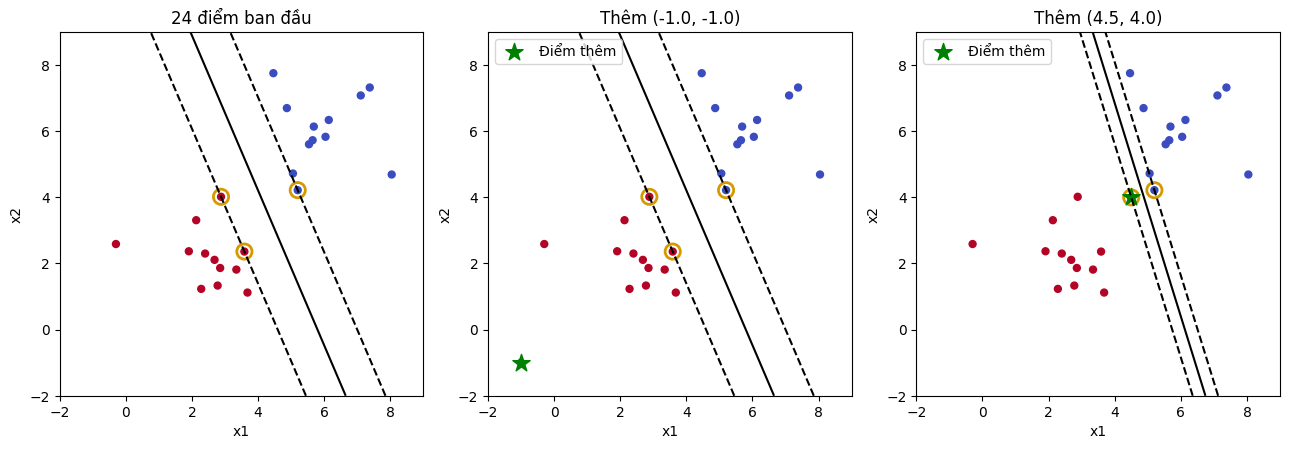

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y

goc = SVC(kernel="linear", C=1000).fit(X, y)
cac_cay = {"24 điểm ban đầu": (goc, X, y)}
print(f"Ban đầu: w1 = {goc.coef_[0, 0]:.6f}, w2 = {goc.coef_[0, 1]:.6f}, b = {goc.intercept_[0]:.6f}")
for diem in [(-1.0, -1.0), (4.5, 4.0)]:
    # Mỗi lần bắt đầu từ 24 điểm gốc, không cộng dồn cả hai điểm.
    X_them = np.vstack([X, diem])
    y_them = np.append(y, 1)
    mh = SVC(kernel="linear", C=1000).fit(X_them, y_them)
    la_ho_tro = len(X) in mh.support_
    print(f"Thêm {diem}, lớp 1: w1 = {mh.coef_[0, 0]:.6f}, "
          f"w2 = {mh.coef_[0, 1]:.6f}, b = {mh.intercept_[0]:.6f}")
    print(f"  Điểm mới là vectơ hỗ trợ: {la_ho_tro}; số vectơ hỗ trợ: {len(mh.support_)}.")
    print(f"  Thay đổi ||w_mới - w_gốc|| = {np.linalg.norm(mh.coef_ - goc.coef_):.6f}; "
          f"|b_mới - b_gốc| = {abs(mh.intercept_[0] - goc.intercept_[0]):.6f}.")
    cac_cay[f"Thêm {diem}"] = (mh, X_them, y_them)
print("Điểm (-1, -1) nằm xa ranh giới, ngoài lề phía lớp 1, nên không trở thành vectơ hỗ trợ và đường ranh giới gần như giữ nguyên.")
print("Điểm (4.5, 4) nằm gần ranh giới cũ và vi phạm lề của lớp 1; nó trở thành vectơ hỗ trợ, buộc đường ranh giới và độ rộng lề thay đổi.")
print("Chênh lệch nhỏ ở trường hợp điểm xa có thể do dung sai của bộ giải, không phải thay đổi đáng kể của nghiệm.")

xx, yy = np.meshgrid(np.linspace(-2, 9, 240), np.linspace(-2, 9, 240))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (ten, (mh, du_lieu, nhan)) in zip(axes, cac_cay.items()):
    f = mh.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(du_lieu[:, 0], du_lieu[:, 1], c=nhan, cmap="coolwarm", s=25)
    ax.scatter(du_lieu[mh.support_, 0], du_lieu[mh.support_, 1], s=120,
               facecolors="none", edgecolors="#d49a00", linewidths=2)
    if len(du_lieu) > 24:
        ax.scatter(*du_lieu[-1], marker="*", s=170, color="green", label="Điểm thêm")
        ax.legend(loc="upper left")
    ax.set(title=ten, xlabel="x1", ylabel="x2", xlim=(-2, 9), ylim=(-2, 9))
    ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "them_mot_diem.png", dpi=150)
plt.show()
plt.close(fig)


## Bài tập 3 — Kernel đa thức

Bậc   C tốt nhất   CV 5 phần   Accuracy kiểm tra
  2            1   0.5422      0.5067


  3            1   0.8178      0.8267


  4          100   0.5156      0.4800
Bậc tốt nhất theo CV: 3, C = 1; accuracy kiểm tra = 0.8267.
RBF của mục 5 trên cùng tập kiểm tra: 0.9200.
Kernel đa thức được chọn chưa vượt RBF; tăng bậc không bảo đảm biên phù hợp với hai vầng trăng.
StandardScaler nằm trong pipeline nên mỗi lượt CV chỉ học phép chuẩn hóa từ phần dữ liệu huấn luyện của lượt đó.


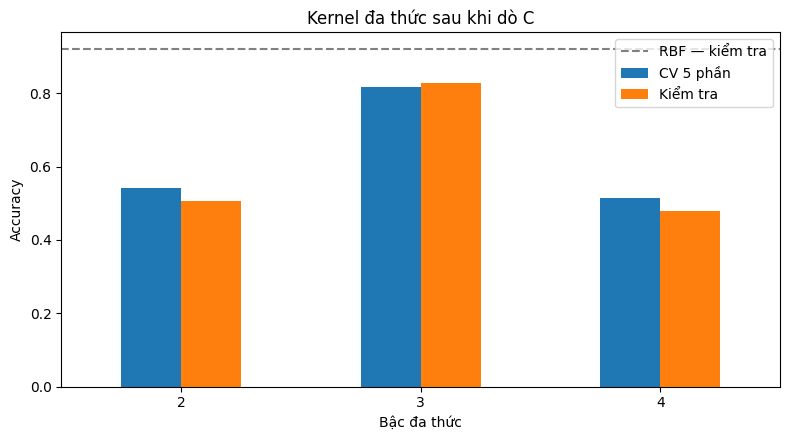

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

ket_qua = []
print("Bậc   C tốt nhất   CV 5 phần   Accuracy kiểm tra")
for bac in [2, 3, 4]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=bac))
    tim = GridSearchCV(mh, {"svc__C": [0.1, 1, 10, 100]}, cv=5)
    tim.fit(X_tr, y_tr)
    ket_qua.append({"bac": bac, "C": tim.best_params_["svc__C"],
                    "cv": tim.best_score_, "kiem_tra": tim.score(X_te, y_te)})
    dong = ket_qua[-1]
    print(f"{bac:3d}   {dong['C']:10g}   {dong['cv']:.4f}      {dong['kiem_tra']:.4f}")
# Chọn bậc theo CV trên tập học, không chọn theo accuracy kiểm tra.
tot_nhat = max(ket_qua, key=lambda dong: dong["cv"])
rbf = SVC(kernel="rbf", C=10, gamma=1).fit(X_tr, y_tr)
accuracy_rbf = rbf.score(X_te, y_te)
print(f"Bậc tốt nhất theo CV: {tot_nhat['bac']}, C = {tot_nhat['C']}; accuracy kiểm tra = {tot_nhat['kiem_tra']:.4f}.")
print(f"RBF của mục 5 trên cùng tập kiểm tra: {accuracy_rbf:.4f}.")
if tot_nhat["kiem_tra"] > accuracy_rbf:
    print("Kernel đa thức được chọn vượt RBF trên tập kiểm tra này.")
elif tot_nhat["kiem_tra"] < accuracy_rbf:
    print("Kernel đa thức được chọn chưa vượt RBF; tăng bậc không bảo đảm biên phù hợp với hai vầng trăng.")
else:
    print("Kernel đa thức được chọn bằng RBF trên tập kiểm tra này, chưa vượt RBF.")
print("StandardScaler nằm trong pipeline nên mỗi lượt CV chỉ học phép chuẩn hóa từ phần dữ liệu huấn luyện của lượt đó.")

bang = pd.DataFrame(ket_qua).set_index("bac")
ax = bang[["cv", "kiem_tra"]].plot.bar(figsize=(8, 4.5), rot=0)
ax.axhline(accuracy_rbf, color="gray", linestyle="--", label="RBF — kiểm tra")
ax.set(xlabel="Bậc đa thức", ylabel="Accuracy", title="Kernel đa thức sau khi dò C")
ax.legend(["RBF — kiểm tra", "CV 5 phần", "Kiểm tra"])
plt.tight_layout()
plt.savefig(thu_muc_hinh / "kernel_da_thuc.png", dpi=150)
plt.show()
plt.close()


## Bài tập 4 — Dò lưới mịn

Lưới thưa: {'C': 10, 'gamma': 1}, CV = 0.8711, kiểm tra = 0.9200


Lưới mịn: {'C': 30, 'gamma': 1}, CV = 0.8756, kiểm tra = 0.9200
Chênh lệch CV mịn - thưa: +0.0044; kiểm tra: +0.0000.
CV lưới mịn cao hơn mốc 0.8711 của tài liệu: True
Accuracy kiểm tra có thay đổi: False
Dò mịn có thể cải thiện điểm CV nhưng không bảo đảm cải thiện tập kiểm tra; cần cân nhắc lợi ích so với số lần huấn luyện tăng thêm.
Tập kiểm tra chỉ dùng để báo cáo sau khi chọn bằng CV; không dùng nó để tiếp tục chỉnh lưới.
Bảng điểm CV lưới mịn:
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533


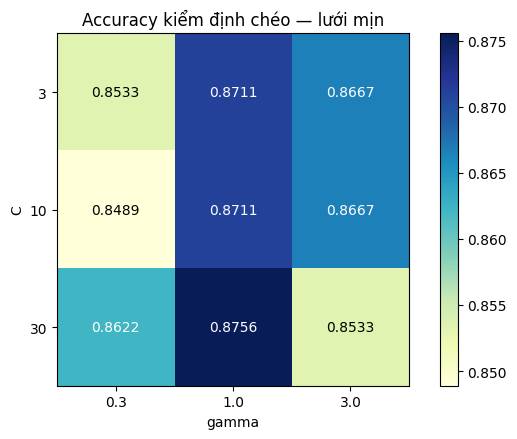

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_thua = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
ket_qua = {}
for ten, luoi in [("Lưới thưa", luoi_thua), ("Lưới mịn", luoi_min)]:
    tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5).fit(X_tr, y_tr)
    ket_qua[ten] = tim
    print(f"{ten}: {tim.best_params_}, CV = {tim.best_score_:.4f}, kiểm tra = {tim.score(X_te, y_te):.4f}")
thua, min_ = ket_qua["Lưới thưa"], ket_qua["Lưới mịn"]
chenh_cv = min_.best_score_ - thua.best_score_
chenh_test = min_.score(X_te, y_te) - thua.score(X_te, y_te)
print(f"Chênh lệch CV mịn - thưa: {chenh_cv:+.4f}; kiểm tra: {chenh_test:+.4f}.")
print("CV lưới mịn cao hơn mốc 0.8711 của tài liệu:", min_.best_score_ > 0.8711 + 0.00005)
print("Accuracy kiểm tra có thay đổi:", abs(chenh_test) > 1e-12)
print("Dò mịn có thể cải thiện điểm CV nhưng không bảo đảm cải thiện tập kiểm tra; cần cân nhắc lợi ích so với số lần huấn luyện tăng thêm.")
print("Tập kiểm tra chỉ dùng để báo cáo sau khi chọn bằng CV; không dùng nó để tiếp tục chỉnh lưới.")

bang = pd.DataFrame(min_.cv_results_["params"])
bang["diem"] = min_.cv_results_["mean_test_score"]
ma_tran = bang.pivot(index="C", columns="gamma", values="diem")
print("Bảng điểm CV lưới mịn:")
print(ma_tran.round(4).to_string())
fig, ax = plt.subplots(figsize=(6.5, 4.5))
anh = ax.imshow(ma_tran, cmap="YlGnBu")
ax.set_xticks(range(3), ma_tran.columns)
ax.set_yticks(range(3), ma_tran.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{ma_tran.iloc[i, j]:.4f}", ha="center", va="center",
                color="white" if ma_tran.iloc[i, j] > .86 else "black")
ax.set(xlabel="gamma", ylabel="C", title="Accuracy kiểm định chéo — lưới mịn")
fig.colorbar(anh, ax=ax)
fig.tight_layout()
fig.savefig(thu_muc_hinh / "luoi_min.png", dpi=150)
plt.show()
plt.close(fig)


## Bài tập 5 — Những chữ số bị nhầm

Bảng nhầm lẫn: hàng là nhãn thật, cột là nhãn dự đoán.
    0   1   2   3   4   5   6   7   8   9
0  45   0   0   0   0   0   0   0   0   0
1   0  46   0   0   0   0   0   0   0   0
2   0   0  44   0   0   0   0   0   0   0
3   0   0   0  46   0   0   0   0   0   0
4   0   0   0   0  44   0   0   0   1   0
5   0   0   0   0   0  46   0   0   0   0
6   0   0   0   0   0   0  45   0   0   0
7   0   0   0   0   0   0   0  44   0   1
8   0   1   0   0   0   0   0   0  42   0
9   0   0   0   1   0   0   0   0   0  44
Các cặp bị nhầm (thật -> dự đoán):
4 -> 8: 1 ảnh
7 -> 9: 1 ảnh
8 -> 1: 1 ảnh
9 -> 3: 1 ảnh


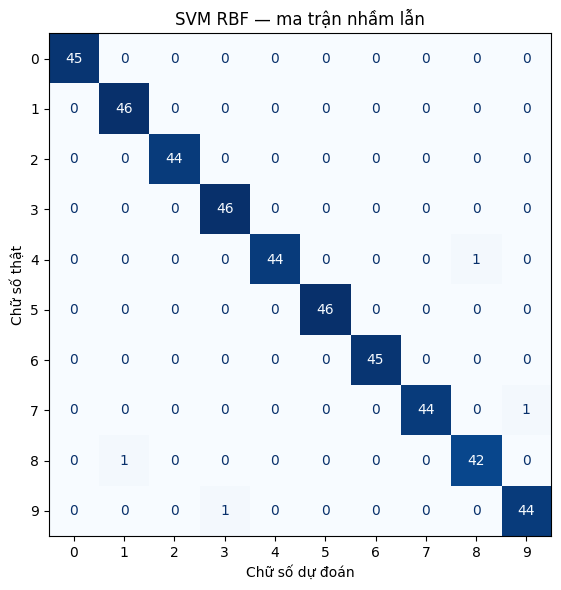

Có 4 ảnh sai trên 450 ảnh kiểm tra.


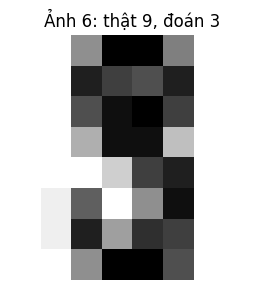

Đã lưu figures/chu_so_sai_006_that_9_doan_3.png


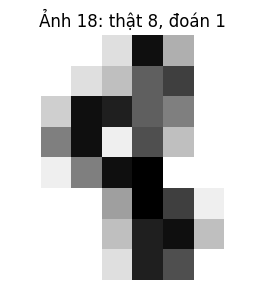

Đã lưu figures/chu_so_sai_018_that_8_doan_1.png


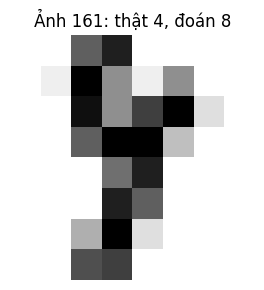

Đã lưu figures/chu_so_sai_161_that_4_doan_8.png


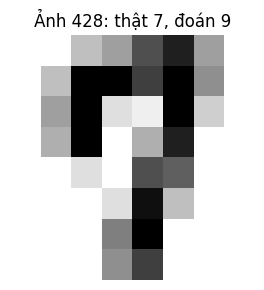

Đã lưu figures/chu_so_sai_428_that_7_doan_9.png
Ảnh chỉ có 8×8 ô nên nét mảnh, nét nối và vòng kín dễ bị mất hoặc dính vào nhau. Các chữ có nét giống nhau như 9 và 3, 8 và 1, 4 và 8, 7 và 9 vì vậy có thể bị nhầm.
Đây là nhận xét trực quan từ các ảnh sai; không thể kết luận nguyên nhân nội tại của mô hình chỉ từ một ảnh.


In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
ma_tran = confusion_matrix(y_te, du_doan, labels=np.arange(10))
print("Bảng nhầm lẫn: hàng là nhãn thật, cột là nhãn dự đoán.")
print(pd.DataFrame(ma_tran, index=range(10), columns=range(10)).to_string())
print("Các cặp bị nhầm (thật -> dự đoán):")
for that in range(10):
    for doan in range(10):
        if that != doan and ma_tran[that, doan] > 0:
            print(f"{that} -> {doan}: {ma_tran[that, doan]} ảnh")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(ma_tran, display_labels=np.arange(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(xlabel="Chữ số dự đoán", ylabel="Chữ số thật", title="SVM RBF — ma trận nhầm lẫn")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "ma_tran_nham_lan.png", dpi=150)
plt.show()
plt.close(fig)

sai = np.flatnonzero(du_doan != y_te)
print(f"Có {len(sai)} ảnh sai trên {len(y_te)} ảnh kiểm tra.")
for i in sai:
    plt.figure(figsize=(3, 3))
    plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    plt.title(f"Ảnh {i}: thật {y_te[i]}, đoán {du_doan[i]}")
    plt.axis("off")
    plt.tight_layout()
    ten_anh = f"chu_so_sai_{i:03d}_that_{y_te[i]}_doan_{du_doan[i]}.png"
    plt.savefig(thu_muc_hinh / ten_anh, dpi=150)
    plt.show()
    plt.close()
    print(f"Đã lưu figures/{ten_anh}")
print("Ảnh chỉ có 8×8 ô nên nét mảnh, nét nối và vòng kín dễ bị mất hoặc dính vào nhau. Các chữ có nét giống nhau như 9 và 3, 8 và 1, 4 và 8, 7 và 9 vì vậy có thể bị nhầm.")
print("Đây là nhận xét trực quan từ các ảnh sai; không thể kết luận nguyên nhân nội tại của mô hình chỉ từ một ảnh.")


## Bài tập 6 — SVM trên dữ liệu lớn

n =  2000, SVC      : 0.058691 giây


n =  2000, LinearSVC: 0.004043 giây


n =  5000, SVC      : 0.297995 giây


n =  5000, LinearSVC: 0.007649 giây


n = 10000, SVC      : 3.450718 giây


n = 10000, LinearSVC: 0.018400 giây


n = 20000, SVC      : 10.605985 giây


n = 20000, LinearSVC: 0.039341 giây


Bảng thời gian fit (giây):
              SVC  LinearSVC
so_mau                      
2000     0.058691   0.004043
5000     0.297995   0.007649
10000    3.450718   0.018400
20000   10.605985   0.039341
Tỷ lệ tăng so với cỡ dữ liệu trước:
2000 -> 5000 (2.5 lần số mẫu): SVC 5.08 lần; LinearSVC 1.89 lần thời gian.
5000 -> 10000 (2.0 lần số mẫu): SVC 11.58 lần; LinearSVC 2.41 lần thời gian.
10000 -> 20000 (2.0 lần số mẫu): SVC 3.07 lần; LinearSVC 2.14 lần thời gian.
Hai lần tăng gấp đôi là 5.000→10.000 và 10.000→20.000 mẫu; 2.000→5.000 là tăng 2,5 lần.
SVC dùng kernel RBF phải xử lý tương tác giữa nhiều cặp mẫu nên thường tốn thời gian hơn khi dữ liệu lớn. LinearSVC dùng bộ giải tuyến tính nên thích hợp hơn với nhiều mẫu khi ranh giới tuyến tính phù hợp.
Các tỷ lệ trên là số đo một lần trên máy hiện tại, không phải quy luật tăng cố định: dữ liệu sinh ở mỗi cỡ khác nhau và thời gian còn phụ thuộc bộ giải, phần cứng, tải máy.


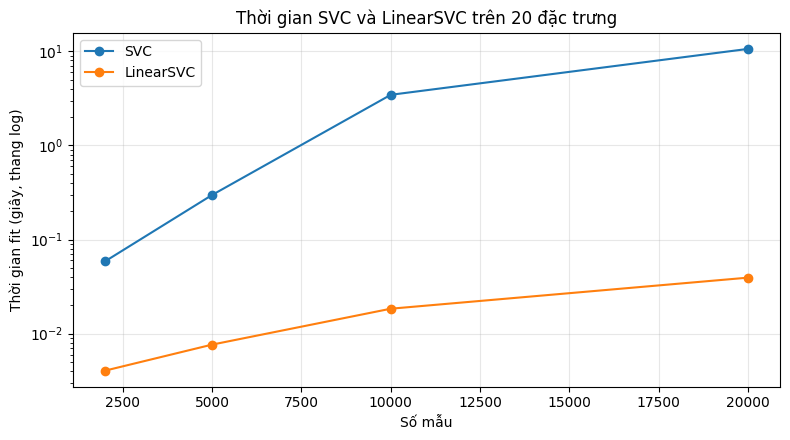

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "sinh_vien.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC

ket_qua = []
for n in [2000, 5000, 10000, 20000]:
    # Sinh dữ liệu ngoài vùng đo; giữ nguyên mô hình mặc định như đề.
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)
    dong = {"so_mau": n}
    for ten, mh in [("SVC", SVC()), ("LinearSVC", LinearSVC())]:
        bat_dau = time.perf_counter()
        mh.fit(X, y)
        dong[ten] = time.perf_counter() - bat_dau
        print(f"n = {n:5d}, {ten:9s}: {dong[ten]:.6f} giây", flush=True)
    ket_qua.append(dong)
bang = pd.DataFrame(ket_qua).set_index("so_mau")
print("Bảng thời gian fit (giây):")
print(bang.round(6).to_string())
print("Tỷ lệ tăng so với cỡ dữ liệu trước:")
for truoc, sau in zip(ket_qua[:-1], ket_qua[1:]):
    he_so_mau = sau["so_mau"] / truoc["so_mau"]
    print(f"{truoc['so_mau']} -> {sau['so_mau']} ({he_so_mau:.1f} lần số mẫu): "
          f"SVC {sau['SVC'] / truoc['SVC']:.2f} lần; "
          f"LinearSVC {sau['LinearSVC'] / truoc['LinearSVC']:.2f} lần thời gian.")
print("Hai lần tăng gấp đôi là 5.000→10.000 và 10.000→20.000 mẫu; 2.000→5.000 là tăng 2,5 lần.")
print("SVC dùng kernel RBF phải xử lý tương tác giữa nhiều cặp mẫu nên thường tốn thời gian hơn khi dữ liệu lớn. LinearSVC dùng bộ giải tuyến tính nên thích hợp hơn với nhiều mẫu khi ranh giới tuyến tính phù hợp.")
print("Các tỷ lệ trên là số đo một lần trên máy hiện tại, không phải quy luật tăng cố định: dữ liệu sinh ở mỗi cỡ khác nhau và thời gian còn phụ thuộc bộ giải, phần cứng, tải máy.")

ax = bang.plot(marker="o", logy=True, figsize=(8, 4.5))
ax.set(xlabel="Số mẫu", ylabel="Thời gian fit (giây, thang log)", title="Thời gian SVC và LinearSVC trên 20 đặc trưng")
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "thoi_gian_svm.png", dpi=150)
plt.show()
plt.close()
